# Customer Segmentation and Customer Lifetime Value Analysis
### Python | Google Colab | UCI Online Retail dataset

**Business problem:** Identify customer groups based on purchasing behavior and recommend ways to improve retention and marketing allocation.

**Dataset:** UCI Online Retail, 541,909 transaction rows. Official source: https://archive.ics.uci.edu/dataset/352/online+retail

**Methods:** data cleaning, exploratory data analysis, RFM features, K-Means clustering, silhouette-based model comparison, customer segment profiling, historical customer value analysis, and business recommendations.

**Important:** This is historical observational data from a UK online retailer, Dec 2010–Dec 2011. Historical spend is not the same as future profit or a guaranteed customer lifetime value. All results are calculated when you run the notebook.

## 1. Install dependencies

In [ ]:
%pip -q install ucimlrepo openpyxl scikit-learn seaborn

## 2. Import libraries and set reproducibility

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

OUTPUT_DIR = "customer_segmentation_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries ready. Output folder:", OUTPUT_DIR)

Libraries ready. Output folder: customer_segmentation_outputs


## 3. Load the official UCI dataset

In [ ]:
# Download the dataset from the UCI repository.
# Internet access is required the first time this cell runs.
online_retail = fetch_ucirepo(id=352)

# The original table typically contains all transaction columns.
df_raw = online_retail.data.original
if df_raw is None or df_raw.empty:
    # Fallback: combine features and target if needed.
    X = online_retail.data.features.copy()
    y = online_retail.data.targets.copy()
    df_raw = pd.concat([X, y], axis=1)

df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

print("Raw dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Raw dataset shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


## 4. Inspect data quality

In [ ]:
print("Data types and non-null counts:")
df.info()

print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\\nNumeric summary:")
display(df.describe(include="all").T.head(20))

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
\nMissing values:


,missing_count
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


\nNumeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Standardize columns and clean transactions

In [ ]:
required = ["InvoiceNo", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Dataset is missing expected columns: {missing_required}")

# Parse values consistently.
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

# Track how many rows are removed at each step so the cleaning is transparent.
cleaning_log = []
cleaning_log.append({"step": "Raw rows", "rows_remaining": len(df), "rows_removed_this_step": 0})

before = len(df)
df = df.dropna(subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"]).copy()
cleaning_log.append({"step": "Drop rows missing required fields", "rows_remaining": len(df), "rows_removed_this_step": before-len(df)})

before = len(df)
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")].copy()
cleaning_log.append({"step": "Remove cancellation invoices (InvoiceNo starts C)", "rows_remaining": len(df), "rows_removed_this_step": before-len(df)})

before = len(df)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
cleaning_log.append({"step": "Keep positive quantities and prices", "rows_remaining": len(df), "rows_removed_this_step": before-len(df)})

df["Sales"] = df["Quantity"] * df["UnitPrice"]
df["CustomerID"] = df["CustomerID"].astype("int64")

cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)
print(f"Clean transaction rows: {len(df):,}")
print(f"Customers represented: {df['CustomerID'].nunique():,}")
print(f"Transaction date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

,step,rows_remaining,rows_removed_this_step
0,Raw rows,541909,0
1,Drop rows missing required fields,406829,135080
2,Remove cancellation invoices (InvoiceNo starts C),397924,8905
3,Keep positive quantities and prices,397884,40


Clean transaction rows: 397,884
Customers represented: 4,338
Transaction date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


### Cleaning decisions
- Rows without a customer ID cannot be used for customer-level segmentation, so they are excluded.
- Cancellation invoices are excluded.
- Rows with non-positive quantity or price are excluded from the positive-sales analysis. This means returns are not modeled as customer negative spend here; the cleaning log documents the exclusions.
- These choices simplify a defensible baseline analysis. For a more advanced extension, returns can be analyzed separately.

## 6. Exploratory data analysis

,InvoiceDate,Revenue
0,2010-12-01,"572,713.89"
1,2011-01-01,"569,445.04"
2,2011-02-01,"447,137.35"
3,2011-03-01,"595,500.76"
4,2011-04-01,"469,200.36"


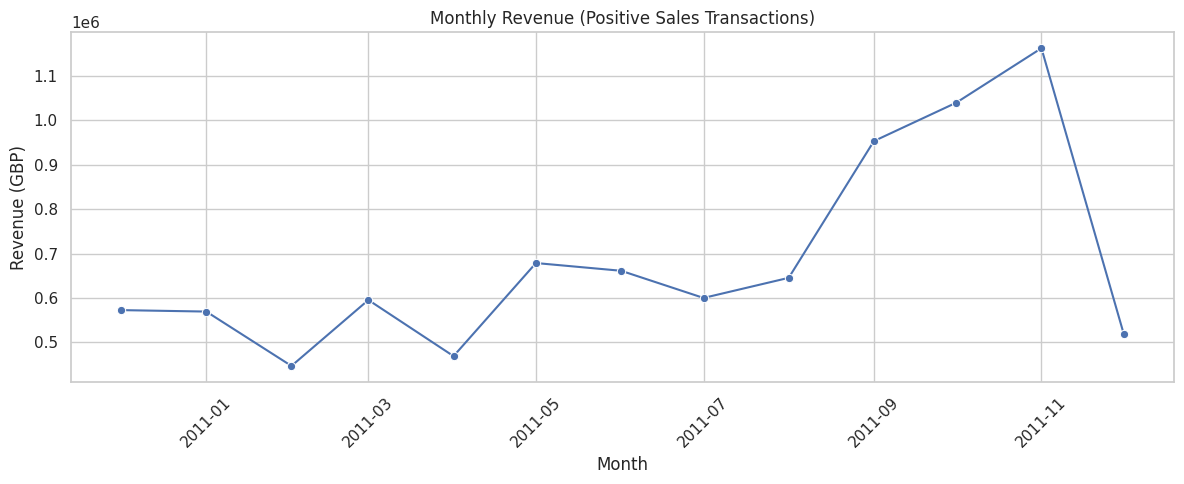

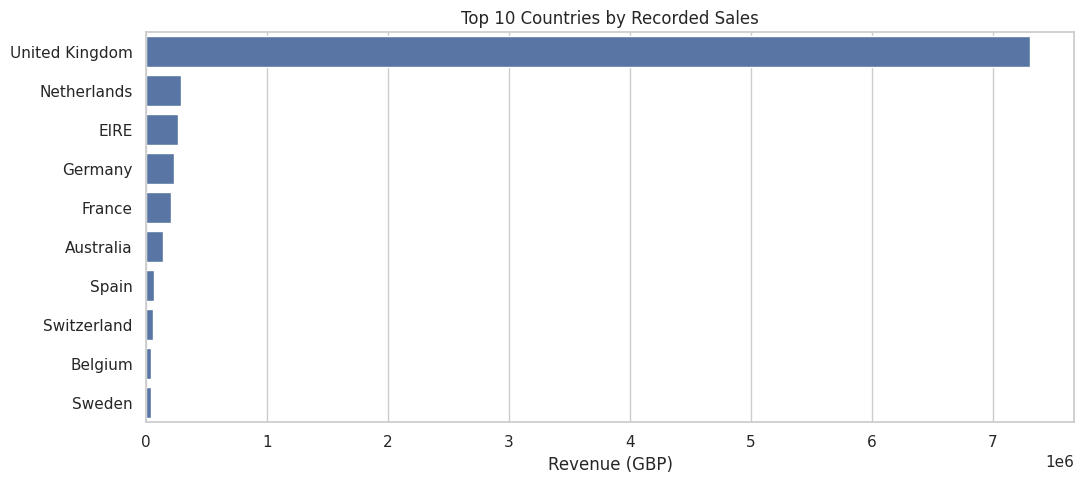

,Metric,Value
0,Clean transaction lines,"397,884.00"
1,Unique invoices,"18,532.00"
2,Unique customers,"4,338.00"
3,Unique products,"3,665.00"
4,Total recorded sales (GBP),"8,911,407.90"


In [ ]:
# Monthly sales trend
monthly_sales = (
    df.set_index("InvoiceDate")
      .resample("MS")["Sales"]
      .sum()
      .rename("Revenue")
      .reset_index()
)
display(monthly_sales.head())

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x="InvoiceDate", y="Revenue", marker="o")
plt.title("Monthly Revenue (Positive Sales Transactions)")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/monthly_revenue.png", dpi=160, bbox_inches="tight")
plt.show()

# Top countries by recorded sales
if "Country" in df.columns:
    country_sales = (df.groupby("Country", as_index=False)["Sales"].sum()
                       .sort_values("Sales", ascending=False).head(10))
    plt.figure(figsize=(11, 5))
    sns.barplot(data=country_sales, x="Sales", y="Country")
    plt.title("Top 10 Countries by Recorded Sales")
    plt.xlabel("Revenue (GBP)")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/top_countries.png", dpi=160, bbox_inches="tight")
    plt.show()

# Transaction and customer-level overview
overview = pd.DataFrame({
    "Metric": ["Clean transaction lines", "Unique invoices", "Unique customers",
               "Unique products", "Total recorded sales (GBP)"],
    "Value": [len(df), df["InvoiceNo"].nunique(), df["CustomerID"].nunique(),
              df["StockCode"].nunique() if "StockCode" in df.columns else np.nan,
              df["Sales"].sum()]
})
display(overview)

## 7. Build customer-level RFM features

In [ ]:
# Use one day after the latest observed transaction as the reference date.
# This makes the recency calculation reproducible for this historical dataset.
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CustomerID")
      .agg(
          LastPurchaseDate=("InvoiceDate", "max"),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("Sales", "sum"),
          TotalUnits=("Quantity", "sum"),
          FirstPurchaseDate=("InvoiceDate", "min")
      )
      .reset_index()
)

rfm["Recency"] = (snapshot_date - rfm["LastPurchaseDate"].dt.normalize()).dt.days
rfm["TenureDays"] = (rfm["LastPurchaseDate"].dt.normalize() - rfm["FirstPurchaseDate"].dt.normalize()).dt.days + 1
rfm["AverageOrderValue"] = rfm["Monetary"] / rfm["Frequency"].replace(0, np.nan)
rfm["Monetary"] = rfm["Monetary"].clip(lower=0)

print("Snapshot date used for recency:", snapshot_date.date())
print("Customer-level RFM shape:", rfm.shape)
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary", "TenureDays", "AverageOrderValue"]].describe().T)

Snapshot date used for recency: 2011-12-10
Customer-level RFM shape: (4338, 9)


,CustomerID,LastPurchaseDate,Frequency,Monetary,TotalUnits,FirstPurchaseDate,Recency,TenureDays,AverageOrderValue
0,12346,2011-01-18 10:01:00,1,"77,183.60",74215,2011-01-18 10:01:00,326,1,"77,183.60"
1,12347,2011-12-07 15:52:00,7,"4,310.00",2458,2010-12-07 14:57:00,3,366,615.71
2,12348,2011-09-25 13:13:00,4,"1,797.24",2341,2010-12-16 19:09:00,76,284,449.31
3,12349,2011-11-21 09:51:00,1,"1,757.55",631,2011-11-21 09:51:00,19,1,"1,757.55"
4,12350,2011-02-02 16:01:00,1,334.40,197,2011-02-02 16:01:00,311,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.00",93.06,100.01,1.00,18.00,51.00,142.75,374.00
Frequency,"4,338.00",4.27,7.70,1.00,1.00,2.00,5.00,209.00
Monetary,"4,338.00","2,054.27","8,989.23",3.75,307.41,674.49,"1,661.74","280,206.02"
TenureDays,"4,338.00",131.77,132.21,1.00,1.00,94.00,253.00,374.00
AverageOrderValue,"4,338.00",419.17,"1,796.54",3.45,178.62,293.90,430.11,"84,236.25"


## 8. Inspect skew and transform RFM variables

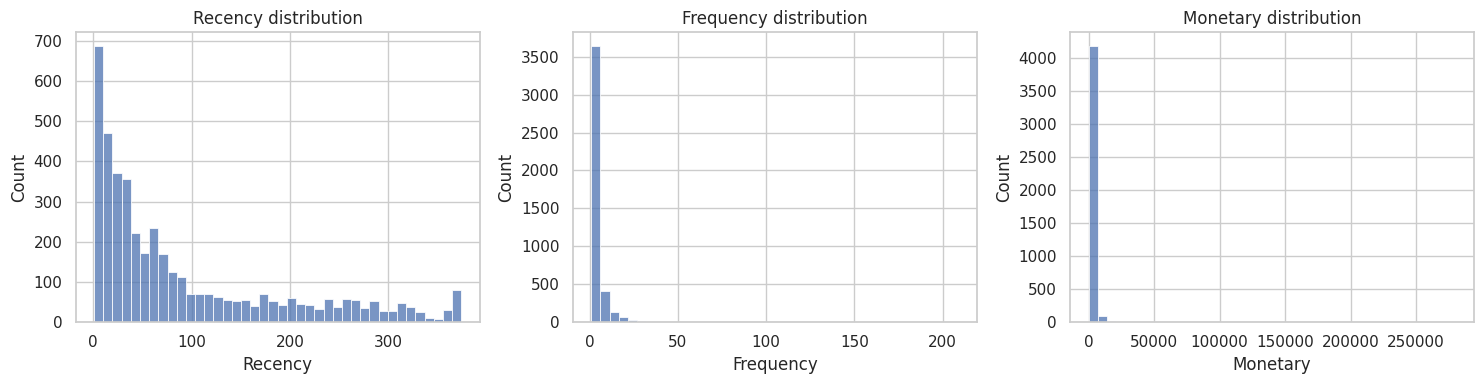

Scaled clustering matrix: (4338, 3)


In [ ]:
rfm_features = ["Recency", "Frequency", "Monetary"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, rfm_features):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"{col} distribution")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/rfm_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

# RFM values are typically right-skewed. log1p reduces skew while preserving zero.
# Keep raw values for interpretation; use transformed values only for clustering.
X_log = np.log1p(rfm[rfm_features].clip(lower=0))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled clustering matrix:", X_scaled.shape)

## 9. Compare candidate K-Means cluster counts

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,"6,474.15",0.43,0.89,"4,380.02"
1,3,"4,856.48",0.34,1.04,"3,640.83"
2,4,"3,924.46",0.34,1.02,"3,346.07"
3,5,"3,268.21",0.32,0.98,"3,230.29"
4,6,"2,840.15",0.32,1.02,"3,103.59"
5,7,"2,533.02",0.31,0.98,"2,986.76"
6,8,"2,325.52",0.30,0.99,"2,843.06"


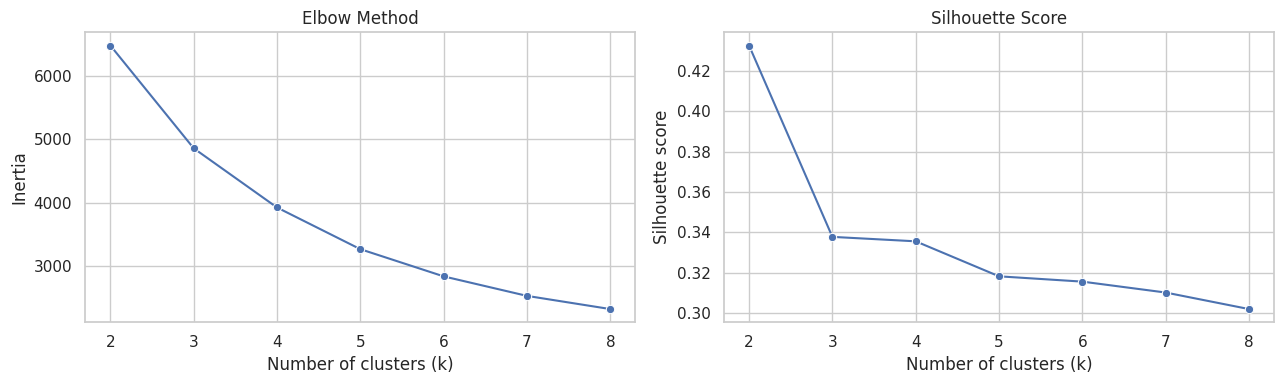

Selected k by highest silhouette score: 2


In [ ]:
# Evaluate k values from 2 through 8 (limited by customer count).
candidate_ks = list(range(2, min(9, len(rfm))))
model_results = []
models = {}

for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = model.fit_predict(X_scaled)
    models[k] = model
    model_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels)
    })

model_scores = pd.DataFrame(model_results)
display(model_scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=model_scores, x="k", y="inertia", marker="o", ax=axes[0])
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

sns.lineplot(data=model_scores, x="k", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/cluster_selection.png", dpi=160, bbox_inches="tight")
plt.show()

# Select the k with the highest silhouette score.
# This is a useful heuristic, not an absolute guarantee of business-optimal segments.
best_k = int(model_scores.loc[model_scores["silhouette"].idxmax(), "k"])
best_model = models[best_k]
rfm["Cluster"] = best_model.predict(X_scaled)

print(f"Selected k by highest silhouette score: {best_k}")

## 10. Profile the customer segments

,Cluster,Customers,AvgRecencyDays,MedianRecencyDays,AvgOrders,MedianOrders,AvgHistoricalSpend,MedianHistoricalSpend,TotalHistoricalSpend,AvgOrderValue,AvgTenureDays,CustomerSharePct,RevenueSharePct
0,0,1669,26.45,17.00,8.44,6.00,"4,544.39","2,062.70","7,584,592.77",574.99,246.72,38.47,85.11
1,1,2669,134.72,96.00,1.67,1.00,497.12,363.70,"1,326,815.13",321.73,59.89,61.53,14.89


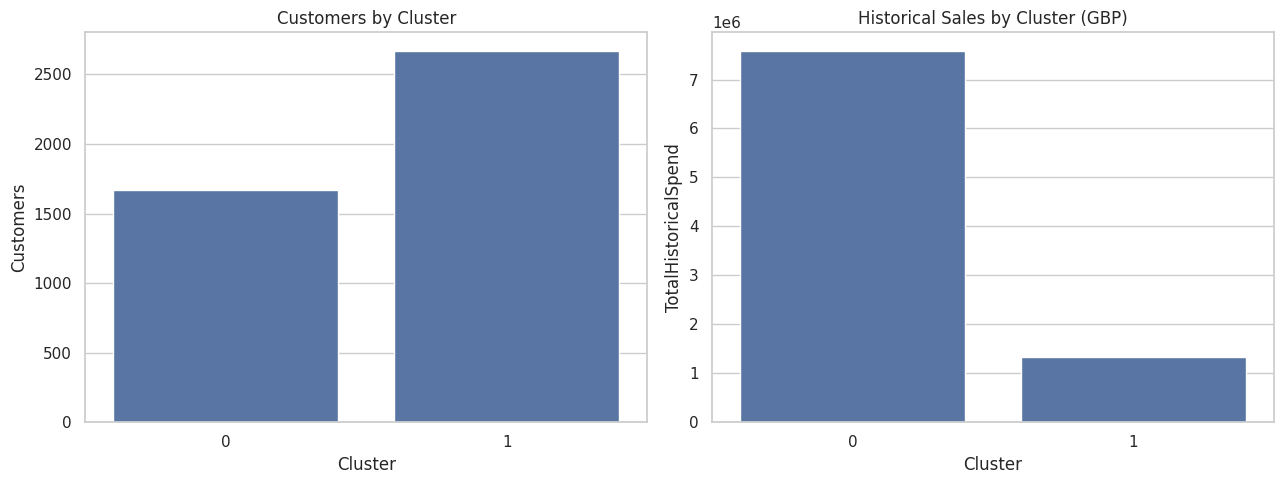

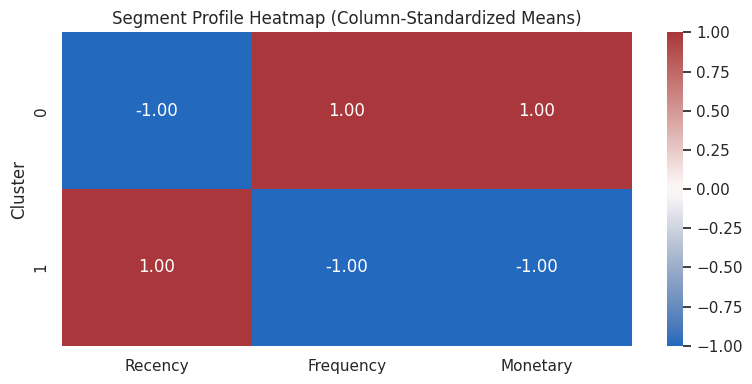

In [ ]:
segment_profile = (
    rfm.groupby("Cluster")
       .agg(
           Customers=("CustomerID", "nunique"),
           AvgRecencyDays=("Recency", "mean"),
           MedianRecencyDays=("Recency", "median"),
           AvgOrders=("Frequency", "mean"),
           MedianOrders=("Frequency", "median"),
           AvgHistoricalSpend=("Monetary", "mean"),
           MedianHistoricalSpend=("Monetary", "median"),
           TotalHistoricalSpend=("Monetary", "sum"),
           AvgOrderValue=("AverageOrderValue", "mean"),
           AvgTenureDays=("TenureDays", "mean")
       )
       .reset_index()
)

total_customers = segment_profile["Customers"].sum()
total_spend = segment_profile["TotalHistoricalSpend"].sum()
segment_profile["CustomerSharePct"] = 100 * segment_profile["Customers"] / total_customers
segment_profile["RevenueSharePct"] = 100 * segment_profile["TotalHistoricalSpend"] / total_spend
segment_profile = segment_profile.sort_values("TotalHistoricalSpend", ascending=False)

display(segment_profile.round(2))
segment_profile.to_csv(f"{OUTPUT_DIR}/segment_profile.csv", index=False)

# Plot customer counts and recorded sales by cluster
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=segment_profile, x="Cluster", y="Customers", ax=axes[0])
axes[0].set_title("Customers by Cluster")
sns.barplot(data=segment_profile, x="Cluster", y="TotalHistoricalSpend", ax=axes[1])
axes[1].set_title("Historical Sales by Cluster (GBP)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/segment_size_and_sales.png", dpi=160, bbox_inches="tight")
plt.show()

# Cluster feature heatmap: mean raw features normalized by column for visualization.
heat = rfm.groupby("Cluster")[rfm_features].mean()
heat_z = (heat - heat.mean()) / heat.std(ddof=0).replace(0, 1)
plt.figure(figsize=(8, 4))
sns.heatmap(heat_z, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Segment Profile Heatmap (Column-Standardized Means)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/segment_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Assign business-readable segment labels

In [ ]:
# Labels are assigned from the cluster profiles, not from cluster ID.
# K-Means cluster numbers have no inherent business meaning.
profile = rfm.groupby("Cluster").agg(
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Customers=("CustomerID", "nunique")
).reset_index()

# A transparent heuristic:
# - Champions: relatively recent, frequent, and high spending
# - At Risk: relatively inactive (high recency) but historically valuable
# - Others: remaining groups, interpreted from their metrics
median_recency = profile["Recency"].median()
median_frequency = profile["Frequency"].median()
median_monetary = profile["Monetary"].median()

def label_cluster(row):
    if row["Recency"] <= median_recency and row["Frequency"] >= median_frequency and row["Monetary"] >= median_monetary:
        return "Champions / High Value"
    if row["Recency"] > median_recency and row["Monetary"] >= median_monetary:
        return "At Risk / Previously Valuable"
    if row["Recency"] <= median_recency and row["Frequency"] < median_frequency:
        return "Recent / Developing"
    return "Occasional / Lower Value"

profile["SegmentName"] = profile.apply(label_cluster, axis=1)
label_map = dict(zip(profile["Cluster"], profile["SegmentName"]))
rfm["Segment"] = rfm["Cluster"].map(label_map)

segment_profile = segment_profile.merge(profile[["Cluster", "SegmentName"]], on="Cluster", how="left")
display(profile.sort_values("Cluster").round(2))
display(rfm[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head(10))

,Cluster,Recency,Frequency,Monetary,Customers,SegmentName
0,0,26.45,8.44,"4,544.39",1669,Champions / High Value
1,1,134.72,1.67,497.12,2669,Occasional / Lower Value


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,"77,183.60",0,Champions / High Value
1,12347,3,7,"4,310.00",0,Champions / High Value
2,12348,76,4,"1,797.24",0,Champions / High Value
3,12349,19,1,"1,757.55",1,Occasional / Lower Value
4,12350,311,1,334.40,1,Occasional / Lower Value
5,12352,37,8,"2,506.04",0,Champions / High Value
6,12353,205,1,89.00,1,Occasional / Lower Value
7,12354,233,1,"1,079.40",1,Occasional / Lower Value
8,12355,215,1,459.40,1,Occasional / Lower Value
9,12356,23,3,"2,811.43",0,Champions / High Value


## 12. Historical customer value and lifetime value caveat

In [ ]:
# Historical monetary value is the sum of observed positive sales in this dataset.
# This is not a forecast of future spend and excludes costs/margins.
historical_value = rfm["Monetary"].sum()
top_20_pct_n = max(1, int(np.ceil(len(rfm) * 0.20)))
top_customers = rfm.nlargest(top_20_pct_n, "Monetary")
top20_spend_share = 100 * top_customers["Monetary"].sum() / historical_value if historical_value else np.nan

value_summary = pd.DataFrame({
    "Metric": [
        "Customers included",
        "Total recorded positive sales (GBP)",
        "Median historical spend per customer (GBP)",
        "Mean historical spend per customer (GBP)",
        "Top 20% of customers' share of recorded sales (%)"
    ],
    "Value": [
        len(rfm),
        historical_value,
        rfm["Monetary"].median(),
        rfm["Monetary"].mean(),
        top20_spend_share
    ]
})
display(value_summary)
value_summary.to_csv(f"{OUTPUT_DIR}/historical_customer_value_summary.csv", index=False)

print("Interpretation note:")
print("Historical spend is observed revenue, not profit or predicted future customer lifetime value.")
print("A robust future CLV model would require a defined forecast horizon and assumptions about repeat purchase, margin, retention, and discount rate.")

,Metric,Value
0,Customers included,"4,338.00"
1,Total recorded positive sales (GBP),"8,911,407.90"
2,Median historical spend per customer (GBP),674.49
3,Mean historical spend per customer (GBP),"2,054.27"
4,Top 20% of customers' share of recorded sales (%),74.62


Interpretation note:
Historical spend is observed revenue, not profit or predicted future customer lifetime value.
A robust future CLV model would require a defined forecast horizon and assumptions about repeat purchase, margin, retention, and discount rate.


## 13. Generate data-backed business recommendations

In [ ]:
# Create recommendations from measured segment behavior.
recommendations = []

for _, row in profile.iterrows():
    name = row["SegmentName"]
    recency = row["Recency"]
    frequency = row["Frequency"]
    monetary = row["Monetary"]

    if "Champions" in name:
        action = "Protect retention with loyalty benefits, early access, and personalized cross-sell; avoid unnecessary discounts."
    elif "At Risk" in name:
        action = "Test a targeted win-back campaign; prioritize customers with high historical spend and measure reactivation."
    elif "Developing" in name:
        action = "Encourage a second purchase with relevant recommendations and a limited, measurable incentive."
    else:
        action = "Use low-cost segmented campaigns; test bundles and track incremental repeat purchases before scaling spend."

    recommendations.append({
        "Cluster": int(row["Cluster"]),
        "Segment": name,
        "AvgRecencyDays": round(recency, 1),
        "AvgOrders": round(frequency, 2),
        "AvgHistoricalSpendGBP": round(monetary, 2),
        "RecommendedAction": action
    })

recommendations_df = pd.DataFrame(recommendations)
display(recommendations_df)
recommendations_df.to_csv(f"{OUTPUT_DIR}/business_recommendations.csv", index=False)

,Cluster,Segment,AvgRecencyDays,AvgOrders,AvgHistoricalSpendGBP,RecommendedAction
0,0,Champions / High Value,26.40,8.44,"4,544.39","Protect retention with loyalty benefits, early..."
1,1,Occasional / Lower Value,134.70,1.67,497.12,Use low-cost segmented campaigns; test bundles...


## 14. Export customer-level results and model outputs

In [ ]:
# Export customer-level segmentation, segment profile, cleaning log, and model scores.
rfm.to_csv(f"{OUTPUT_DIR}/customer_segments.csv", index=False)
cleaning_summary.to_csv(f"{OUTPUT_DIR}/cleaning_log.csv", index=False)
model_scores.to_csv(f"{OUTPUT_DIR}/model_selection_scores.csv", index=False)
recommendations_df.to_csv(f"{OUTPUT_DIR}/business_recommendations.csv", index=False)

print("Files created:")
for name in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", name)

Files created:
 - business_recommendations.csv
 - cleaning_log.csv
 - cluster_selection.png
 - customer_segments.csv
 - historical_customer_value_summary.csv
 - model_selection_scores.csv
 - monthly_revenue.png
 - rfm_distributions.png
 - segment_heatmap.png
 - segment_profile.csv
 - segment_size_and_sales.png
 - top_countries.png


## 15. Download all outputs as a ZIP

In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("customer_segmentation_outputs", "zip", OUTPUT_DIR)
print("ZIP created:", zip_path)
files.download(zip_path)

ZIP created: /content/customer_segmentation_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Conclusion template (complete after running)

Use actual notebook outputs to write the conclusion:
1. State how many customer records were included after cleaning.
2. Report the selected cluster count and its silhouette score.
3. Describe each segment using observed recency, frequency, and historical spend.
4. Identify the segment contributing the largest share of recorded sales.
5. Recommend specific marketing actions and state that their impact should be tested.
6. Explicitly note limitations: one-year historical window, excluded anonymous transactions, excluded cancellations/non-positive rows, no costs/margins, and no causal experiment.

## Dataset citation
Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

## Reproducibility notes
- Random seed is fixed at 42.
- The cluster count is selected by highest silhouette score among k=2 to 8 (where available).
- Segment names are heuristic interpretations of cluster-level averages; always inspect the profile table before presenting them as conclusions.
- Do not claim estimated marketing ROI without a controlled experiment or explicit cost/benefit assumptions.

## 17. Generate an animated, interactive HTML dashboard

Run this cell after all previous analysis cells. It creates a standalone HTML dashboard from the actual results in this notebook, with KPI cards, interactive Plotly charts, and automatically generated interpretations. The dashboard is saved as `Customer_Segmentation_Interactive_Dashboard.html` and downloaded in Google Colab.

The HTML uses Plotly from a CDN for interactive charts, so an internet connection is needed to load the chart library when viewing the HTML. All analysis values and chart data are embedded from this run of the notebook.


In [ ]:
%pip -q install plotly

import json
import html as html_lib
import plotly.express as px
import plotly.graph_objects as go
from google.colab import files

# Recalculate dashboard summaries from the current, real analysis results.
segment_dashboard = (
    rfm.groupby("Segment", dropna=False)
       .agg(
           Customers=("CustomerID", "nunique"),
           AvgRecencyDays=("Recency", "mean"),
           AvgOrders=("Frequency", "mean"),
           AvgHistoricalSpend=("Monetary", "mean"),
           TotalHistoricalSpend=("Monetary", "sum")
       )
       .reset_index()
)
segment_dashboard["CustomerSharePct"] = 100 * segment_dashboard["Customers"] / segment_dashboard["Customers"].sum()
segment_dashboard["RevenueSharePct"] = 100 * segment_dashboard["TotalHistoricalSpend"] / max(segment_dashboard["TotalHistoricalSpend"].sum(), 1e-9)
segment_dashboard = segment_dashboard.sort_values("TotalHistoricalSpend", ascending=False)

total_customers_dash = int(rfm["CustomerID"].nunique())
total_revenue_dash = float(rfm["Monetary"].sum())
avg_spend_dash = float(rfm["Monetary"].mean())
avg_orders_dash = float(rfm["Frequency"].mean())
segment_count_dash = int(rfm["Segment"].nunique())
top_segment_row = segment_dashboard.iloc[0]
largest_segment_row = segment_dashboard.sort_values("Customers", ascending=False).iloc[0]
least_recent_row = segment_dashboard.sort_values("AvgRecencyDays", ascending=False).iloc[0]

# Generate chart HTML fragments from actual data.
fig_revenue = px.bar(
    segment_dashboard, x="Segment", y="TotalHistoricalSpend",
    color="Segment", title="Historical Sales by Customer Segment",
    labels={"TotalHistoricalSpend": "Historical sales (GBP)", "Segment": "Segment"},
    hover_data={"Customers": True, "RevenueSharePct": ":.1f", "TotalHistoricalSpend": ":,.2f"}
)
fig_revenue.update_layout(showlegend=False, template="plotly_white", margin=dict(l=20,r=20,t=60,b=100), transition={"duration": 600})
fig_revenue.update_xaxes(tickangle=-20)

fig_customers = px.pie(
    segment_dashboard, names="Segment", values="Customers",
    title="Customer Distribution by Segment", hole=0.58
)
fig_customers.update_layout(template="plotly_white", margin=dict(l=20,r=20,t=60,b=20), transition={"duration": 600})

fig_scatter = px.scatter(
    rfm, x="Recency", y="Monetary", color="Segment",
    size="Frequency", hover_data=["CustomerID", "Frequency", "AverageOrderValue"],
    title="Customer Map: Recency vs Historical Spend",
    labels={"Recency":"Days since last purchase", "Monetary":"Historical spend (GBP)", "Frequency":"Distinct invoices"}
)
fig_scatter.update_layout(template="plotly_white", margin=dict(l=20,r=20,t=60,b=50), transition={"duration": 600})
fig_scatter.update_yaxes(type="log", title="Historical spend (GBP, log scale)")

profile_means = rfm.groupby("Segment")[["Recency","Frequency","Monetary"]].mean()
profile_z = (profile_means - profile_means.mean()) / profile_means.std(ddof=0).replace(0, 1)
fig_heat = px.imshow(
    profile_z, text_auto=".2f", aspect="auto", color_continuous_scale="RdBu_r",
    zmin=-2, zmax=2, title="Segment Profile (standardized mean RFM values)",
    labels=dict(x="RFM metric", y="Segment", color="Relative level")
)
fig_heat.update_layout(template="plotly_white", margin=dict(l=20,r=20,t=60,b=30))

chart_revenue = fig_revenue.to_html(full_html=False, include_plotlyjs=False, config={"responsive": True, "displaylogo": False})
chart_customers = fig_customers.to_html(full_html=False, include_plotlyjs=False, config={"responsive": True, "displaylogo": False})
chart_scatter = fig_scatter.to_html(full_html=False, include_plotlyjs=False, config={"responsive": True, "displaylogo": False})
chart_heat = fig_heat.to_html(full_html=False, include_plotlyjs=False, config={"responsive": True, "displaylogo": False})

def money_gbp(value):
    return f"£{value:,.2f}"

kpis = [
    ("Customers analyzed", f"{total_customers_dash:,}", "Unique customers with usable transaction history"),
    ("Recorded sales", money_gbp(total_revenue_dash), "Positive sales transactions; not profit"),
    ("Avg. historical spend", money_gbp(avg_spend_dash), "Mean observed spend per analyzed customer"),
    ("Customer segments", f"{segment_count_dash}", "K-Means-derived groups with business-readable labels"),
]
kpi_cards = "".join(
    f'<article class="kpi"><div class="kpi-label">{html_lib.escape(label)}</div>'
    f'<div class="kpi-value">{html_lib.escape(value)}</div><div class="kpi-note">{html_lib.escape(note)}</div></article>'
    for label, value, note in kpis
)

interpretations = [
    f"The segment contributing the most observed sales is <strong>{html_lib.escape(str(top_segment_row['Segment']))}</strong>, with {money_gbp(float(top_segment_row['TotalHistoricalSpend']))} in recorded sales ({float(top_segment_row['RevenueSharePct']):.1f}% of analyzed sales).",
    f"The largest segment by customer count is <strong>{html_lib.escape(str(largest_segment_row['Segment']))}</strong>, representing {int(largest_segment_row['Customers']):,} customers ({float(largest_segment_row['CustomerSharePct']):.1f}% of the analyzed base).",
    f"The segment with the highest average days since last purchase is <strong>{html_lib.escape(str(least_recent_row['Segment']))}</strong> ({float(least_recent_row['AvgRecencyDays']):.1f} days on average). Consider testing a targeted win-back campaign and measuring its results.",
    "Historical spend is a backward-looking measure. This dataset alone does not establish future lifetime value, profit, or causal impact from marketing."
]
interpretation_html = "".join(f"<li>{item}</li>" for item in interpretations)

segment_table = segment_dashboard[[
    "Segment","Customers","CustomerSharePct","AvgRecencyDays","AvgOrders",
    "AvgHistoricalSpend","TotalHistoricalSpend","RevenueSharePct"
]].copy()
for col in ["CustomerSharePct","RevenueSharePct","AvgRecencyDays","AvgOrders","AvgHistoricalSpend","TotalHistoricalSpend"]:
    segment_table[col] = segment_table[col].astype(float).round(2)
table_html = segment_table.to_html(index=False, classes="data-table", border=0, escape=True)

dashboard_html = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Customer Intelligence | Segmentation & Historical Value</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
:root{{--bg:#f3f5fb;--panel:#fff;--ink:#16213a;--muted:#69748a;--line:#e2e7f0;--accent:#4f46e5;--accent2:#06b6d4}}
*{{box-sizing:border-box}}body{{margin:0;background:radial-gradient(circle at top left,#e5eaff 0,#f3f5fb 42%,#eef8fb 100%);color:var(--ink);font:15px/1.55 Inter,ui-sans-serif,system-ui,-apple-system,Segoe UI,Roboto,sans-serif}}
header{{padding:42px max(22px,calc((100vw - 1240px)/2));background:linear-gradient(125deg,#111b3a,#283b73 60%,#0f766e);color:white;position:relative;overflow:hidden}}
header:after{{content:"";position:absolute;width:340px;height:340px;border-radius:50%;right:5%;top:-210px;background:#ffffff14;animation:float 8s ease-in-out infinite}}
.eyebrow{{text-transform:uppercase;letter-spacing:.16em;font-size:11px;font-weight:800;color:#b8c7ff}}
h1{{font-size:clamp(30px,4vw,48px);line-height:1.08;margin:10px 0 12px;max-width:850px}}
header p{{color:#dbe5ff;max-width:780px;margin:0}}
main{{max-width:1280px;margin:0 auto;padding:24px 20px 60px}}
.kpis{{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:15px;margin-top:-2px}}
.kpi,.panel{{background:var(--panel);border:1px solid var(--line);border-radius:18px;box-shadow:0 12px 35px #1725540a}}
.kpi{{padding:20px;animation:rise .7s both;transition:transform .25s,box-shadow .25s}}.kpi:hover{{transform:translateY(-5px);box-shadow:0 18px 35px #17255415}}
.kpi:nth-child(2){{animation-delay:.08s}}.kpi:nth-child(3){{animation-delay:.16s}}.kpi:nth-child(4){{animation-delay:.24s}}
.kpi-label{{font-size:12px;font-weight:700;color:var(--muted);text-transform:uppercase;letter-spacing:.07em}}
.kpi-value{{font-size:clamp(23px,2.5vw,34px);font-weight:800;letter-spacing:-.04em;margin:8px 0 4px;overflow-wrap:anywhere}}
.kpi-note,.muted{{color:var(--muted);font-size:12px}}
.grid{{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:18px;margin-top:18px}}
.panel{{padding:20px;min-width:0;animation:rise .65s both}}.panel h2{{font-size:18px;margin:0 0 5px}}.panel p{{color:var(--muted);margin:0 0 10px;font-size:13px}}
.chart{{width:100%;min-height:360px}}
.insights{{padding-left:20px;margin:10px 0 0}}.insights li{{margin:11px 0}}.table-wrap{{overflow:auto;margin-top:14px}}
.data-table{{border-collapse:collapse;width:100%;font-size:13px;white-space:nowrap}}.data-table th,.data-table td{{padding:11px 12px;border-bottom:1px solid var(--line);text-align:left}}.data-table th{{background:#f7f8fc;color:#4b5873;position:sticky;top:0}}
.note{{background:#eef2ff;border:1px solid #dbe3ff;padding:14px 16px;border-radius:12px;color:#33416c;font-size:13px;margin-top:16px}}
footer{{color:var(--muted);font-size:12px;text-align:center;padding:25px}}
@keyframes rise{{from{{opacity:0;transform:translateY(14px)}}to{{opacity:1;transform:translateY(0)}}}}@keyframes float{{0%,100%{{transform:translateY(0)}}50%{{transform:translateY(18px)}}}}
@media(max-width:850px){{.kpis{{grid-template-columns:repeat(2,minmax(0,1fr))}}.grid{{grid-template-columns:1fr}}header{{padding:32px 20px}}}}
@media(max-width:480px){{.kpis{{grid-template-columns:1fr}}main{{padding:16px 12px 40px}}.kpi,.panel{{padding:16px}}}}
@media(prefers-reduced-motion:reduce){{*,*:before,*:after{{animation:none!important;transition:none!important;scroll-behavior:auto!important}}}}
</style></head>
<body>
<header><div class="eyebrow">Business Intelligence · Customer Analytics</div>
<h1>Customer Segmentation &amp; Historical Value</h1>
<p>Evidence-led view of customer purchasing behavior, segment contribution, and retention opportunities. Generated from the notebook's actual analysis outputs.</p></header>
<main>
<section class="kpis">{kpi_cards}</section>
<section class="grid">
<article class="panel"><h2>Revenue contribution</h2><p>Which segment accounts for the most recorded sales?</p><div class="chart">{chart_revenue}</div></article>
<article class="panel"><h2>Customer distribution</h2><p>How the analyzed customer base is distributed across segments.</p><div class="chart">{chart_customers}</div></article>
<article class="panel"><h2>Customer behavior map</h2><p>Each point is a customer. Hover to inspect observed RFM behavior; spend uses a logarithmic axis.</p><div class="chart">{chart_scatter}</div></article>
<article class="panel"><h2>Segment profile heatmap</h2><p>Column-standardized segment averages: positive values are above the overall segment mean.</p><div class="chart">{chart_heat}</div></article>
</section>
<section class="panel" style="margin-top:18px"><h2>Automatically generated interpretations</h2><p>Interpretations below are calculated from the data loaded in this run.</p><ul class="insights">{interpretation_html}</ul></section>
<section class="panel" style="margin-top:18px"><h2>Segment-level summary</h2><p>Values are derived from customer-level RFM and cluster labels.</p><div class="table-wrap">{table_html}</div></section>
<div class="note"><strong>Methodology &amp; limitations:</strong> Customer segmentation uses RFM features and K-Means. Recency is measured relative to one day after the latest transaction date in the dataset. Revenue represents recorded positive sales, not profit. Missing customer IDs, cancellation invoices, and non-positive quantities/prices are excluded from this baseline. The historical dataset spans approximately one year; future customer lifetime value and causal marketing impact are not established by this analysis.</div>
</main><footer>Generated from UCI Online Retail data · For academic and analytical use · Refresh by rerunning the notebook</footer>
</body></html>"""

dashboard_path = "Customer_Segmentation_Interactive_Dashboard.html"
with open(dashboard_path, "w", encoding="utf-8") as f:
    f.write(dashboard_html)

print("Interactive dashboard created:", dashboard_path)
print("File size (KB):", round(os.path.getsize(dashboard_path) / 1024, 1))
files.download(dashboard_path)

Interactive dashboard created: Customer_Segmentation_Interactive_Dashboard.html
File size (KB): 206.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>